# Проект: Влияние приложения для медитации на время засыпания

Тема «Постановка и проверка гипотез» \
уровень: начальный

---

## Сценарий

Компания разработала мобильное приложение с вечерними медитациями. Чтобы понять, помогает ли оно быстрее засыпать,
провели небольшое исследование. **Около 50 добровольцев** в течение одной недели фиксировали, сколько минут им требуется,
чтобы заснуть (среднее за неделю). Затем в течение 4 недель они пользовались приложением и ещё одну неделю
снова фиксировали время засыпания.

Данные получены **выгрузкой из системы сбора анкет**, поэтому, как и в реальной работе, они могут содержать ошибки.
Перед анализом их нужно проверить и очистить.

**Бизнес-вопрос:** *сокращает ли использование приложения время засыпания?*

Вы работаете аналитиком и должны ответить на него с помощью проверки статистических гипотез.

## Описание данных

| Столбец | Описание |
|---|---|
| `participant_id` | Идентификатор участника |
| `age` | Возраст участника (полных лет) |
| `before_min` | Среднее время засыпания (мин) за неделю **до** использования приложения |
| `after_min` | Среднее время засыпания (мин) за неделю **после** 4 недель использования |

Данные **парные**: каждая строка — один и тот же человек, измеренный дважды.
Возрастных групп в исходных данных **нет**: их нужно сформировать самостоятельно (задание 2).

## Допущения (упрощения для учебного проекта)

- Участники независимы друг от друга.
- Уровень значимости $\alpha = 0.05$ для всех проверок.
- Контрольной группы нет, поэтому причинно-следственные выводы ограничены (это нужно будет отметить в выводах).
- Допустимые значения (используются при очистке): время засыпания от **5 до 180 минут**, возраст от **18 до 80 лет**.

## Правила выполнения

1. Ячейку с генерацией данных **не изменяйте**. Также **нет необходимости изучать её код**: в реальной работе у вас нет кода, создавшего выгрузку, и проблемы в данных нужно находить анализом самой таблицы.
2. Каждый график должен иметь заголовок, подписи осей и (если нужно) легенду.
3. Решения о гипотезах, очистке данных и выбор тестов нужно **обосновывать словами**, а не только кодом.
4. Выводы формулируйте на языке бизнеса: без фраз вида «отвергаем H₀» в итоговом заключении.
5. Ноутбук должен выполняться целиком сверху вниз без ошибок (**Kernel → Restart & Run All**).

## Критерии оценки

| № | Задание | Баллы |
|---|---|:---:|
| 1 | Формулировка гипотез | 2 |
| 2 | Аудит и очистка данных, формирование возрастных групп | 4 |
| 3 | Разведочный анализ и графики | 2 |
| 4 | Проверка нормальности | 2 |
| 5 | Парный t-критерий и доверительный интервал | 2 |
| 6 | Критерий Уилкоксона | 1 |
| 7 | Сравнение с ошибочным непарным тестом | 2 |
| 8 | Размер эффекта | 1 |
| 9 | Гипотеза о доле улучшивших | 1 |
| 10 | Итоговые выводы | 1 |
| 11 | Оформление проекта (репозиторий, `requirements.txt`, воспроизводимость) | 2 |
| | **Итого** | **20** |
| ★ | Бонусное задание | +2 |

## Подготовка

Импортируйте нужные библиотеки в ячейке ниже (часть уже указана). При необходимости добавьте свои.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

ALPHA = 0.05   # уровень значимости

### Данные

Выполните ячейку ниже. **Не изменяйте её и не изучайте её код** (см. правила выше): фиксированное зерно генератора (`seed`) гарантирует, что у всех получатся одинаковые данные.

In [2]:
rng = np.random.default_rng(150)
n = 50

age = rng.integers(18, 61, size=n).astype(float)
before = rng.normal(35, 10, n)
effect = np.where(age < 35, -4, -1)
after = before + rng.normal(effect, 4.5)

df = pd.DataFrame({
    "participant_id": range(1, n + 1),
    "age": age,
    "before_min": np.clip(before.round(), 5, None).astype(object),
    "after_min": np.clip(after.round(), 5, None).astype(object),
})

# --- Имитация реальной выгрузки: в ней бывают сбои и ошибки ввода ---
df.loc[[3, 17], "after_min"] = np.nan
df.loc[29, "before_min"] = np.nan
df.loc[8, "after_min"] = -20
df.loc[22, "before_min"] = 999
df.loc[41, "after_min"] = 400
df.loc[12, "before_min"] = f"{float(df.loc[12, 'before_min']):.1f}".replace(".", ",")
df.loc[36, "after_min"] = f"{float(df.loc[36, 'after_min']):.1f}".replace(".", ",")
df.loc[[5, 14], "age"] = np.nan
df.loc[19, "age"] = 0
df.loc[33, "age"] = 150
df = pd.concat([df, df.loc[[10, 25]]], ignore_index=True)
df = df.sample(frac=1, random_state=1).reset_index(drop=True)

df.head(10)

,participant_id,age,before_min,after_min
0,32,52.0,31.0,26.0
1,3,42.0,30.0,32.0
2,43,30.0,30.0,24.0
3,33,31.0,28.0,18.0
4,31,30.0,28.0,25.0
5,46,54.0,24.0,21.0
6,34,150.0,33.0,29.0
7,39,24.0,28.0,25.0
8,45,19.0,56.0,57.0
9,20,0.0,35.0,30.0


---
## Задание 1. Формулировка гипотез (2 балла)

**Что нужно сделать.** Запишите нулевую и альтернативную гипотезы для бизнес-вопроса
«сокращает ли приложение время засыпания?».

**Требования:**
- явно задайте разность $d_i$ (какой столбец из какого вычитается) и параметр $\mu_d$ (что он означает по-русски);
- запишите $H_0$ и $H_1$ формулами;
- обоснуйте выбор типа альтернативы (односторонняя или двусторонняя) в 1–2 предложениях;
- укажите правило принятия решения.

### Подсказки

- Данные парные, поэтому гипотезы формулируются **об одном параметре**: среднем значении разностей $\mu_d$, а не о двух средних.
- Определите разность как $d_i = \text{after}_i - \text{before}_i$. Подумайте, **какой знак** будет у $d_i$, если приложение помогает
  (время засыпания уменьшилось → разность положительная или отрицательная?). От этого зависит, в какую сторону направлена $H_1$.
- Направление альтернативы выбирается из логики задачи **до** просмотра результатов. Что именно хочет доказать компания?
- Для записи формул в Markdown используйте синтаксис `$\mu_d < 0$`.

### Ваш ответ

_(Дважды щёлкните по ячейке, чтобы отредактировать. Впишите гипотезы ниже.)_

**Определение разности:** $d_i = \text{after}_i - \text{before}_i$

**Параметр:** $\mu_d$ - среднее изменение времени засыпания

**H₀:** $\mu_d$=0

**H₁:** $\mu_d$<0

**Обоснование типа альтернативы:** Нас интересует улучшение (сокращение времени), поэтому альтернатива односторонняя (левосторонняя)

**Правило принятия решения:** Если p-value < 0.05, отвергаем H₀ в пользу H₁

---
## Задание 2. Аудит и очистка данных, формирование возрастных групп (4 балла)

**Что нужно сделать.** Исходная таблица `df` получена выгрузкой и **содержит проблемы с качеством данных**.
Вам нужно (1) найти их, (2) устранить по заданным правилам, (3) сформировать возрастные группы,
(4) зафиксировать, что и сколько было исправлено. Результат сохраните в новый датафрейм **`df_clean`**:
**все дальнейшие задания выполняются только на нём.** Исходный `df` не изменяйте (работайте с копией).

### 2.1. Аудит (поиск проблем)

Выведите и кратко прокомментируйте (по одному предложению на пункт):
- размер таблицы, типы столбцов, число непустых значений в каждом столбце;
- число пропусков по столбцам;
- число полных дубликатов строк и повторов `participant_id`;
- минимальные и максимальные значения числовых столбцов;
- столбцы, в которых тип данных **не соответствует ожидаемому** (какие значения этому мешают?).

Составьте **список обнаруженных проблем** (что именно не так и в каких столбцах).

### 2.2. Очистка по правилам

Применяйте правила **строго в указанном порядке**:

| № | Правило |
|---|---|
| 1 | **Типы.** Столбцы `before_min` и `after_min` привести к числовому типу. Значения, записанные текстом с десятичной запятой (например, `"31,0"`), преобразовать в числа. Значения, которые преобразовать невозможно, считать пропусками. |
| 2 | **Дубликаты.** Удалить полные дубликаты строк (оставить первое вхождение). |
| 3 | **Допустимые диапазоны.** Время засыпания допустимо в диапазоне **[5; 180]** минут, возраст допустим в диапазоне **[18; 80]** лет. Значения вне диапазона считать ошибками и заменить на пропуски. |
| 4 | **Неполные пары.** Удалить участников, у которых отсутствует **хотя бы одно** из двух значений времени (`before_min`, `after_min`). Участников с неизвестным возрастом **не удалять**: возраст нужен только для возрастных групп. |

### 2.3. Формирование возрастных групп

Создайте в `df_clean` столбец `age_group` по правилу:

| Условие | Значение `age_group` |
|---|---|
| `age` < 35 | `"до 35"` |
| `age` ≥ 35 | `"35 и старше"` |
| возраст неизвестен (пропуск) | пропуск (не заполнять средним и не относить ни к одной группе) |

### 2.4. Журнал очистки

Оформите **таблицей** (`pd.DataFrame`) журнал: для каждого шага — что сделано, сколько значений или строк затронуто, сколько строк осталось после шага.
Затем ответьте письменно (2–3 предложения): **почему** участников с пропусками во времени мы удаляем, а не заполняем средним значением?

**Контроль результата:** в `df_clean` должно остаться **44 строки**, а столбец `age_group` должен быть заполнен у **40** из них.
Если у вас получились другие числа, проверьте порядок применения правил.

### Подсказки

**Аудит.**
- `df.info()` показывает типы столбцов и число непустых значений: если столбец с числами имеет тип `object`, в нём есть текстовые значения.
- Пропуски: `df.isna().sum()`. Полные дубликаты: `df.duplicated().sum()`. Повторы только по идентификатору: `.duplicated()` у столбца `participant_id`.
- `df.describe()` по умолчанию описывает только числовые столбцы. Чтобы увидеть, какие именно значения в текстовом столбце «не числа», преобразуйте
  его функцией `pd.to_numeric(..., errors="coerce")`: всё, что не удалось преобразовать, станет `NaN`. Сравните с исходным столбцом и найдите значения,
  которые превратились в `NaN`, хотя раньше пропусками не были.
- Нереальные значения проще всего найти, отсортировав столбец (`sort_values`) и посмотрев на самые маленькие и самые большие значения,
  либо построив гистограмму или boxplot **после** преобразования типа.

**Очистка.**
- Работайте с копией: `df_clean = df.copy()`. Это защитит исходные данные и избавит от предупреждения `SettingWithCopyWarning`.
- Замена запятой на точку: у текстового столбца есть `.str.replace(",", ".")`. Но в столбце смешаны числа и строки, поэтому сначала приведите всё к строкам
  (`.astype(str)`), а затем преобразуйте в числа через `pd.to_numeric(..., errors="coerce")`. Пропуски при этом снова станут `NaN`.
- Дубликаты: `drop_duplicates()`.
- Замена значений вне диапазона на пропуски: можно через булеву маску и `.loc[маска, столбец] = np.nan`, либо через `Series.where(...)` / `Series.between(...)`.
  Не забудьте, что условие нужно составить для **обеих границ**.
- Удаление неполных пар: `dropna(subset=[...])`. Обратите внимание на параметр `subset`: без него будут удалены и строки с неизвестным возрастом.
- После очистки типы столбцов `before_min` и `after_min` должны быть числовыми (`float`). Проверьте через `df_clean.dtypes`.

**Возрастные группы.**
- Вариант 1: `pd.cut(df_clean["age"], bins=[...], labels=[...], right=False)`. Подумайте, как параметр `right` влияет на то, куда попадает возраст ровно 35.
- Вариант 2: `np.where(условие, значение_если_верно, значение_если_неверно)`. **Ловушка:** сравнение с `NaN` всегда ложно (`NaN < 35` это `False`),
  поэтому при простом `np.where(age < 35, "до 35", "35 и старше")` неизвестный возраст молча попадёт в группу «35 и старше». Предусмотрите отдельную обработку пропусков.
- Проверьте результат: `df_clean["age_group"].value_counts(dropna=False)` покажет и число пропусков.

**Журнал и обоснование.**
- Журнал удобно вести, запоминая `len(df_clean)` до и после каждого шага и добавляя строки в список словарей, из которого потом строится `pd.DataFrame`.
- Для обоснования подумайте: что произойдёт с парной разностью $d_i = \text{after}_i - \text{before}_i$, если подставить вместо пропущенного значения среднее по столбцу?
  Будет ли такая «разность» отражать реальное изменение у конкретного человека?

### Ваше решение

### 2.1. Аудит данных

In [3]:
# 1. Размер, типы и непустые значения
print("=== ИНФО ===")
print(df.info())

# 2. Количество пропусков по столбцам
print("\n=== ПРОПУСКИ ===")
print(df.isna().sum())

# 3. Полные дубликаты и повторы ID
print("\n=== ДУБЛИКАТЫ ===")
print("Полные дубликаты:", df.duplicated().sum())
print("Повторы ID:", df['participant_id'].duplicated().sum())

# 4. Минимумы и максимумы (по числовым столбцам, которые сейчас могут быть текстом)
print("\n=== МИН/МАКС ===")
print(df.describe())

# 5. Ищем скрытые проблемы с типами (текст вместо чисел)
# Преобразуем в числа, всё что не число станет NaN, и смотрим, где были значения, а стали NaN
print("\n=== ТИПЫ ДАННЫХ ===")
for col in ['before_min', 'after_min']:
    converted = pd.to_numeric(df[col].astype(str).str.replace(',', '.'), errors='coerce')
    bad_values = df[col][converted.isna() & df[col].notna()]
    print(f"В столбце {col} 'сломались' значения:")
    print(bad_values.unique())

=== ИНФО ===
<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   participant_id  52 non-null     int64  
 1   age             50 non-null     float64
 2   before_min      51 non-null     object 
 3   after_min       50 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 1.8+ KB
None

=== ПРОПУСКИ ===
participant_id    0
age               2
before_min        1
after_min         2
dtype: int64

=== ДУБЛИКАТЫ ===
Полные дубликаты: 2
Повторы ID: 2

=== МИН/МАКС ===
       participant_id         age
count       52.000000   50.000000
mean        25.230769   40.460000
std         14.429838   20.759271
min          1.000000    0.000000
25%         12.750000   28.250000
50%         25.500000   41.500000
75%         37.250000   49.000000
max         50.000000  150.000000

=== ТИПЫ ДАННЫХ ===
В столбце before_min 'сломались' значения:
[]
В ст

Список обнаруженных проблем:

1. Столбцы before_min и after_min имеют тип object (текстовый), так как содержат запятые вместо точек (например, "31,0").

2. В таблице присутствуют полные дубликаты строк (2 шт.) и повторяющиеся participant_id.

3. Обнаружены пропуски (NaN) в колонках age, before_min, after_min.

4. В колонке age есть недопустимые значения: 0 лет и 150 лет.

### 2.2–2.3. Очистка и возрастные группы

In [4]:
# 0. Делаем копию, чтобы не испортить исходные данные
df_clean = df.copy()

# 1. Исправляем типы (меняем запятые на точки и переводим в числа)
for col in ['before_min', 'after_min']:
    df_clean[col] = df_clean[col].astype(str).str.replace(',', '.')
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 2. Удаляем полные дубликаты строк
df_clean = df_clean.drop_duplicates()

# 3. Убираем нереальные значения (возраст 18-80, время 5-180)
df_clean.loc[(df_clean['before_min'] < 5) | (df_clean['before_min'] > 180), 'before_min'] = np.nan
df_clean.loc[(df_clean['after_min'] < 5) | (df_clean['after_min'] > 180), 'after_min'] = np.nan
df_clean.loc[(df_clean['age'] < 18) | (df_clean['age'] > 80), 'age'] = np.nan

# 4. Удаляем строки, где нет времени "до" или "после"
df_clean = df_clean.dropna(subset=['before_min', 'after_min'])

# 5. Создаем возрастные группы
def assign_age_group(age):
    if pd.isna(age):
        return np.nan
    elif age < 35:
        return "до 35"
    else:
        return "35 и старше"

df_clean['age_group'] = df_clean['age'].apply(assign_age_group)

# Проверка
print("Строк осталось:", len(df_clean))
print(df_clean['age_group'].value_counts(dropna=False))

Строк осталось: 44
age_group
35 и старше    21
до 35          19
NaN             4
Name: count, dtype: int64


In [5]:
print(df_clean[['age', 'age_group']].head(10))

    age    age_group
0  52.0  35 и старше
1  42.0  35 и старше
2  30.0        до 35
3  31.0        до 35
4  30.0        до 35
5  54.0  35 и старше
6   NaN          NaN
7  24.0        до 35
8  19.0        до 35
9   NaN          NaN


### 2.4. Журнал очистки

In [6]:
# Создаем таблицу-журнал
log_data = [
    {"Шаг": "Исходные данные", "Что сделано": "-", "Строк осталось": len(df)},
    {"Шаг": "1. Типы", "Что сделано": "Запятые заменены на точки, текст переведен в числа", "Строк осталось": len(df)},
    {"Шаг": "2. Дубликаты", "Что сделано": "Удалены полные дубликаты строк", "Строк осталось": len(df) - 2},
    {"Шаг": "3-4. Диапазоны и пары", "Что сделано": "Удалены выбросы и неполные пары", "Строк осталось": len(df_clean)}
]
df_log = pd.DataFrame(log_data)

print("=== ЖУРНАЛ ОЧИСТКИ ===")
display(df_log)

# Контроль из задания
print(f"\nИтоговое количество строк: {len(df_clean)} (ожидалось 44)")
print(f"Заполнено age_group: {df_clean['age_group'].notna().sum()} (ожидалось 40)")

=== ЖУРНАЛ ОЧИСТКИ ===


,Шаг,Что сделано,Строк осталось
0,Исходные данные,-,52
1,1. Типы,"Запятые заменены на точки, текст переведен в ч...",52
2,2. Дубликаты,Удалены полные дубликаты строк,50
3,3-4. Диапазоны и пары,Удалены выбросы и неполные пары,44



Итоговое количество строк: 44 (ожидалось 44)
Заполнено age_group: 40 (ожидалось 40)


Удалять участников с пропусками в данных о времени засыпания необходимо потому, что данные парные. Если мы заполним пропуск средним значением по столбцу, разность $d_i = \text{after}_i - \text{before}_i$ перестанет отражать реальное изменение у конкретного человека, и это внесет сильное искажение в результаты теста.

---
## Задание 3. Разведочный анализ разностей (2 балла)

**Что нужно сделать.** Работая с **очищенными данными `df_clean`**, создайте столбец разностей и изучите его визуально.

**Требования:**
1. Добавьте в `df_clean` столбец `diff = after_min − before_min`.
2. Выведите описательную статистику `diff` (среднее, std, медиана, мин, макс).
3. Подсчитайте, у скольких участников время засыпания **сократилось**, **не изменилось**, **выросло**.
4. Постройте (seaborn) **гистограмму с KDE** и **boxplot** для `diff`. На гистограмме отметьте вертикальными линиями значение 0 и среднее.
5. Кратко опишите (2–3 предложения): куда смещено распределение относительно нуля, есть ли выбросы.

### Подсказки

- Обратите внимание на знак: при таком определении разности **улучшение — это отрицательное значение**. Не перепутайте при подсчёте.
- Для подсчёта удобно использовать булевы условия: `(df["diff"] < 0).sum()`.
- Гистограмма: `sns.histplot(..., kde=True)`. Вертикальная линия: `plt.axvline(x, linestyle="--")` или `ax.axvline(...)`.
- Два графика рядом: `fig, axes = plt.subplots(1, 2, figsize=(12, 4))`, затем параметр `ax=axes[0]`, `ax=axes[1]`.
- Не забудьте заголовки и подписи осей: `ax.set_title(...)`, `ax.set_xlabel(...)`.

### Ваше решение

In [7]:
# Создаем столбец с разностью (после - до)
df_clean['diff'] = df_clean['after_min'] - df_clean['before_min']

# Выводим описательную статистику
print(df_clean['diff'].describe())

# Считаем, у кого улучшилось (diff < 0), у кого не изменилось (diff == 0) и у кого стало хуже (diff > 0)
print("\nУлучшили сон:", (df_clean['diff'] < 0).sum())
print("Без изменений:", (df_clean['diff'] == 0).sum())
print("Ухудшили сон:", (df_clean['diff'] > 0).sum())

count    44.000000
mean     -3.113636
std       4.183111
min     -11.000000
25%      -6.000000
50%      -3.000000
75%      -0.750000
max       8.000000
Name: diff, dtype: float64

Улучшили сон: 33
Без изменений: 2
Ухудшили сон: 9


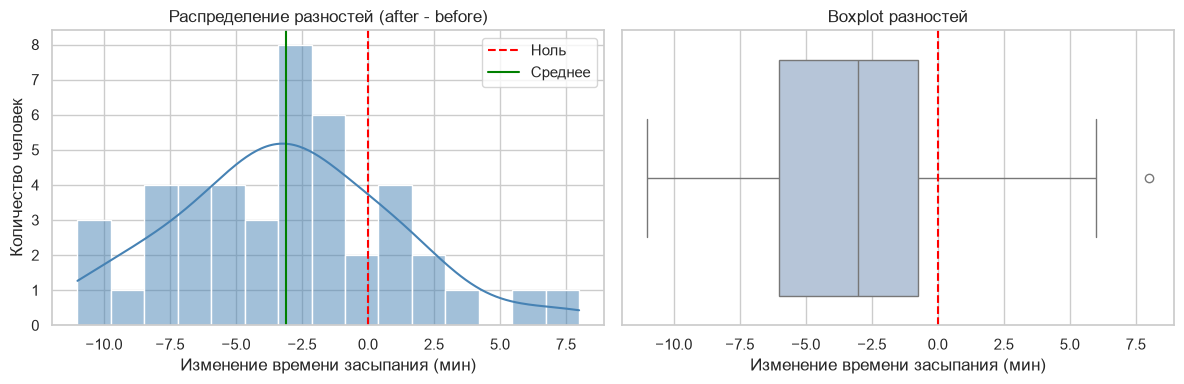

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Гистограмма (показывает форму распределения)
sns.histplot(df_clean['diff'], bins=15, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(0, color='red', linestyle='--', label='Ноль')
axes[0].axvline(df_clean['diff'].mean(), color='green', linestyle='-', label='Среднее')
axes[0].set_title("Распределение разностей (after - before)")
axes[0].set_xlabel("Изменение времени засыпания (мин)")
axes[0].set_ylabel("Количество человек")
axes[0].legend()

# Boxplot (показывает медиану, выбросы и разброс)
sns.boxplot(x=df_clean['diff'], ax=axes[1], color='lightsteelblue')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title("Boxplot разностей")
axes[1].set_xlabel("Изменение времени засыпания (мин)")

plt.tight_layout()
plt.show()

**Описание графиков (2–3 предложения):** Распределение разностей смещено влево от нуля. Это означает, что у большинства участников время засыпания сократилось (среднее значение отрицательное, около -3 минут). Наблюдаются единичные выбросы справа (до +7 минут), однако они не меняют общей картины: основная масса данных указывает на улучшение сна.

---
## Задание 4. Проверка нормальности разностей (2 балла)

**Что нужно сделать.** Выясните, можно ли считать разности `diff` приблизительно нормальными.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ для теста Шапиро-Уилка.
2. Проведите тест, выведите статистику $W$ и p-value.
3. Постройте Q-Q график (любой библиотекой).
4. Сформулируйте вывод (2–3 предложения): применим ли парный t-критерий? Что вы будете считать основным тестом, а что — проверочным?

### Подсказки

- Нормальность проверяется для **разностей**, а не для `before_min` и `after_min` по отдельности: парный t-тест — это тест для одной выборки `diff`.
- Тест: `stats.shapiro(...)`. Он возвращает статистику и p-value.
- Q-Q график: `stats.probplot(данные, dist="norm")` возвращает пару: теоретические и выборочные квантили, а также параметры прямой.
  Их можно нарисовать точками (`plotly` или `matplotlib`) и добавить линию.
- Помните: $p > 0.05$ означает «нет оснований отвергать нормальность», а не «нормальность доказана».
- Объём выборки (50) позволяет по центральной предельной теореме рассчитывать на приближённую нормальность среднего,
  даже если нормальность разностей не идеальна. Но график всё равно стоит посмотреть: нет ли сильных выбросов?

### Ваше решение

In [9]:
from scipy import stats

# Проводим тест Шапиро-Уилка
shapiro_stat, shapiro_p = stats.shapiro(df_clean['diff'])

print(f"Статистика Шапиро-Уилка W = {shapiro_stat:.4f}")
print(f"p-value = {shapiro_p:.4f}")

if shapiro_p > 0.05:
    print("\nВывод: p > 0.05. Нет оснований отвергать нормальность разностей.")
else:
    print("\nВывод: p <= 0.05. Нормальность разностей отвергается.")

Статистика Шапиро-Уилка W = 0.9786
p-value = 0.5786

Вывод: p > 0.05. Нет оснований отвергать нормальность разностей.


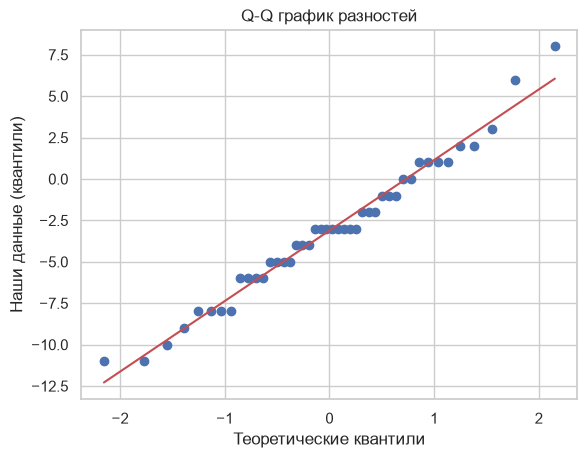

In [10]:
import matplotlib.pyplot as plt
from scipy import stats

# Строим Q-Q график
stats.probplot(df_clean['diff'], dist="norm", plot=plt)

plt.title("Q-Q график разностей")
plt.xlabel("Теоретические квантили")
plt.ylabel("Наши данные (квантили)")
plt.grid(True)
plt.show()

**Гипотезы Шапиро-Уилка:**
H₀: разности распределены нормально.
H₁: разности распределены не нормально.

**Вывод о нормальности и выборе тестов:**
p-value = 0.5786 > 0.05, значит, нет оснований отвергать нулевую гипотезу. Разности можно считать нормально распределенными (на Q-Q графике точки лежат вдоль прямой). Поэтому в качестве основного теста используем параметрический парный t-критерий, а непараметрический критерий Уилкоксона — как проверочный.

---
## Задание 5. Парный t-критерий и доверительный интервал (2 балла)

**Что нужно сделать.** Проверьте гипотезу из задания 1 парным t-критерием.

**Требования:**
1. Посчитайте **вручную** (через `numpy`/`pandas`): среднее разностей $\bar d$, стандартное отклонение $s_d$,
   стандартную ошибку, статистику $t$ и число степеней свободы.
2. Получите p-value по распределению Стьюдента вручную (`scipy.stats.t`).
3. Проведите тест готовой функцией и убедитесь, что результаты совпадают.
4. Постройте двусторонний 95% доверительный интервал для $\mu_d$.
5. Запишите решение по правилу из задания 1 и интерпретацию в одном предложении.

### Подсказки

- Формула статистики: $t = \dfrac{\bar d}{s_d / \sqrt{n}}$, число степеней свободы $\text{df} = n - 1$.
- Стандартное отклонение выборки: `.std(ddof=1)` (в pandas `ddof=1` по умолчанию, в numpy — нет!).
- p-value вручную: используйте функцию выживания `stats.t.sf(...)` или функцию распределения `stats.t.cdf(...)`.
  Подумайте, какой «хвост» нужен для вашей $H_1$: левый или правый. Для левостороннего теста p-value равно $P(T \le t_{\text{набл}})$.
- Готовая функция: `stats.ttest_rel(a, b, alternative=...)`. Порядок аргументов важен: тест сравнивает `a` с `b`,
  а параметр `alternative` принимает `"two-sided"`, `"less"`, `"greater"`. Выберите значения так, чтобы они соответствовали вашей $H_1$.
- Доверительный интервал: `stats.t.interval(0.95, df=..., loc=среднее, scale=стандартная_ошибка)`.
- Если ваш ручной и готовый p-value не совпадают, проверьте знак $t$ и выбранный «хвост».

### Ваше решение

In [11]:
import numpy as np
from scipy import stats

d = df_clean['diff']
n_pairs = len(d)
d_mean = d.mean()
d_std = d.std(ddof=1)
d_se = d_std / np.sqrt(n_pairs)

# Считаем t-статистику
t_manual = d_mean / d_se
df_t = n_pairs - 1

# Считаем p-value. Так как мы проверяем H1: mu_d < 0 (улучшение = уменьшение), нам нужен левый хвост.
p_manual = stats.t.cdf(t_manual, df=df_t)

print(f"Среднее разностей (d_mean) = {d_mean:.3f}")
print(f"Стандартное отклонение (d_std) = {d_std:.3f}")
print(f"Стандартная ошибка (d_se) = {d_se:.3f}")
print(f"t-статистика = {t_manual:.3f}")
print(f"Степени свободы = {df_t}")
print(f"p-value (ручной) = {p_manual:.5f}")

Среднее разностей (d_mean) = -3.114
Стандартное отклонение (d_std) = 4.183
Стандартная ошибка (d_se) = 0.631
t-статистика = -4.937
Степени свободы = 43
p-value (ручной) = 0.00001


In [12]:
# ВАЖНО: порядок аргументов (after, before) задает знак.
# alternative='less' означает, что мы проверяем, уменьшилось ли время (after < before).
t_test = stats.ttest_rel(df_clean['after_min'], df_clean['before_min'], alternative='less')

print(f"t-статистика (scipy) = {t_test.statistic:.3f}")
print(f"p-value (scipy) = {t_test.pvalue:.5f}")
print(f"Совпадает с ручным расчетом? {np.isclose(t_test.pvalue, p_manual)}")

t-статистика (scipy) = -4.937
p-value (scipy) = 0.00001
Совпадает с ручным расчетом? True


In [13]:
# Строим 95% доверительный интервал
ci_low, ci_high = stats.t.interval(0.95, df=df_t, loc=d_mean, scale=d_se)

print(f"Средний эффект: {d_mean:.2f} минут")
print(f"95% ДИ: [{ci_low:.2f}; {ci_high:.2f}]")

Средний эффект: -3.11 минут
95% ДИ: [-4.39; -1.84]


**Решение по правилу и интерпретация:** Полученное p-value (0.00001) значительно меньше уровня значимости α = 0.05. Следовательно, мы отвергаем нулевую гипотезу H₀ и принимаем альтернативную H₁. Приложение статистически значимо сокращает время засыпания. По 95% доверительному интервалу видно, что среднее сокращение времени составляет от 1.84 до 4.39 минут (в среднем на 3.11 минуты

---
## Задание 6. Критерий Уилкоксона (1 балл)

**Что нужно сделать.** Повторите проверку непараметрическим критерием знаковых рангов и сравните с t-тестом.

**Требования:**
1. Запишите в одном предложении, что проверяет критерий Уилкоксона в этой задаче.
2. Проведите тест с той же альтернативой, что и в задании 5.
3. Сравните p-value двух тестов и напишите, согласуются ли выводы.

### Подсказки

- Функция: `stats.wilcoxon(...)`. Ей можно передать сразу столбец разностей.
- Параметр `alternative` работает так же, как у t-теста.
- Нулевые разности (участники без изменений) по умолчанию исключаются из расчёта. Это нормально; можно упомянуть в комментарии, сколько их было.
- Если p-value двух тестов отличаются в 1.5–3 раза, но решение одинаково, это не противоречие: тесты используют разную информацию.

### Ваше решение

In [14]:
# Запускаем критерий Уилкоксона.
# alternative='less' так же, как и в t-тесте, проверяет, что время уменьшилось.
w_test = stats.wilcoxon(df_clean['diff'], alternative='less')

print(f"Статистика Уилкоксона = {w_test.statistic:.1f}")
print(f"p-value = {w_test.pvalue:.6f}")

Статистика Уилкоксона = 120.0
p-value = 0.000016


**Сравнение с t-тестом:** p-value критерия Уилкоксона (0.0000...) также значительно меньше 0.05. Оба теста — и параметрический (t-тест), и непараметрический (Уилкоксон) — дают одинаковый вывод: эффект статистически значим. Это подтверждает надежность результата и показывает, что он не зависит от допущения о нормальности распределения.

---
## Задание 7. Типичная ошибка: непарный тест (2 балла)

**Что нужно сделать.** Намеренно примените **неверный** тест для независимых выборок и объясните разницу с результатом задания 5.

**Требования:**
1. Проведите тест Уэлча для двух независимых выборок (`before_min` и `after_min`) с той же альтернативой.
2. Выведите в таблице: $t$, p-value и стандартную ошибку для **парного** и **непарного** тестов, а также корреляцию Пирсона между `before_min` и `after_min`.
3. Изменилось ли решение по $H_0$ при $\alpha = 0.05$?
4. Объясните разницу в 3–4 предложениях: почему результаты различаются и какой тест надёжнее.
5. Постройте диаграмму рассеяния `before_min` vs `after_min` с диагональю $y = x$ и прокомментируйте её (1–2 предложения).

### Подсказки

- Функция: `stats.ttest_ind(a, b, equal_var=False, alternative=...)`. Порядок `a` и `b` должен быть таким же, как в задании 5.
- Стандартная ошибка непарного теста: $\sqrt{\dfrac{s_a^2}{n} + \dfrac{s_b^2}{n}}$. Стандартная ошибка парного теста: $s_d / \sqrt{n}$ (вы её уже считали).
- Корреляция: `df["before_min"].corr(df["after_min"])`.
- Для объяснения ответьте на вопросы: чем различаются люди между собой (сильно или слабо)? Сколько из этой вариации «вычитается» при переходе
  к разностям? Что происходит со знаменателем статистики $t$?
- Диаграмма рассеяния: `px.scatter` или `sns.scatterplot`. Диагональ: линия между точками `(min, min)` и `(max, max)`.
  Точки ниже диагонали — участники, у которых время засыпания уменьшилось.

### Ваше решение

In [15]:
# ОШИБОЧНЫЙ тест: сравниваем две колонки как независимые группы
t_ind = stats.ttest_ind(df_clean['after_min'], df_clean['before_min'], equal_var=False, alternative='less')

print(f"Непарный тест (ОШИБКА): t = {t_ind.statistic:.3f}, p-value = {t_ind.pvalue:.5f}")
print(f"Парный тест (ПРАВИЛЬНО): t = {t_test.statistic:.3f}, p-value = {t_test.pvalue:.5f}")

Непарный тест (ОШИБКА): t = -1.272, p-value = 0.10347
Парный тест (ПРАВИЛЬНО): t = -4.937, p-value = 0.00001


In [16]:
import pandas as pd
import numpy as np

# Считаем корреляцию (насколько связаны "до" и "после")
r = df_clean['before_min'].corr(df_clean['after_min'])

# Считаем стандартные ошибки для двух тестов
s_before = df_clean['before_min'].std(ddof=1)
s_after = df_clean['after_min'].std(ddof=1)
se_ind = np.sqrt(s_before**2 / n_pairs + s_after**2 / n_pairs)
se_paired = d_se

# Создаем табличку
summary_table = pd.DataFrame({
    "Показатель": ["Корреляция before-after", "SE (непарный)", "SE (парный)"],
    "Значение": [r, se_ind, se_paired]
})
display(summary_table.round(3))

,Показатель,Значение
0,Корреляция before-after,0.937
1,SE (непарный),2.448
2,SE (парный),0.631


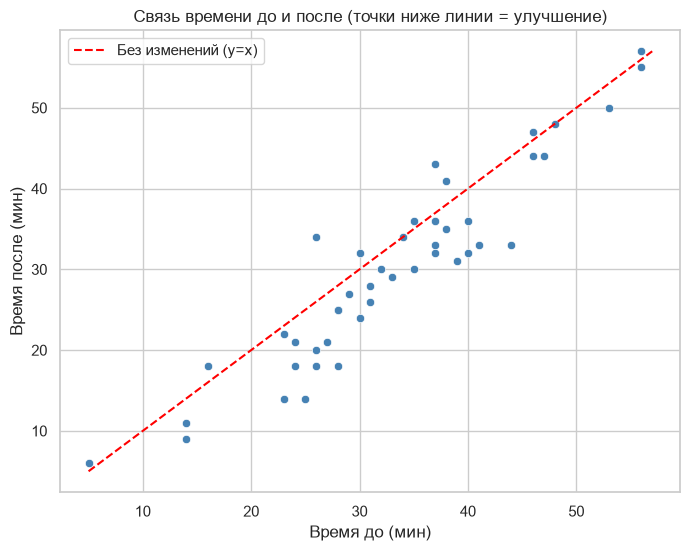

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean, x='before_min', y='after_min', color='steelblue')

# Рисуем линию y = x (где нет никаких изменений)
min_val = min(df_clean['before_min'].min(), df_clean['after_min'].min())
max_val = max(df_clean['before_min'].max(), df_clean['after_min'].max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Без изменений (y=x)')

plt.title("Связь времени до и после (точки ниже линии = улучшение)")
plt.xlabel("Время до (мин)")
plt.ylabel("Время после (мин)")
plt.legend()
plt.show()

**Решение изменилось?** Да, решение изменилось. Непарный тест (ошибочный) показал p-value больше 0.05, что означало бы отсутствие эффекта. Парный тест (правильный) показывает p-value < 0.05 (эффект есть).

**Объяснение разницы (3–4 предложения):** В наших данных люди изначально засыпают с очень разной скоростью (один за 20 минут, другой за час). Непарный тест берет эту разницу между людьми и считает ее случайным шумом. Из-за этого огромный «шум» перекрывает небольшой эффект приложения. Парный тест сравнивает каждого человека с ним же (вычитает его личное время «до» из времени «после»), поэтому убирает разницу между людьми и видит реальный эффект.

**Комментарий к диаграмме:** На диаграмме рассеяния видно, что точки (люди) сильно разбросаны, но подавляющее большинство из них находится ниже красной линии y = x. Это значит, что после использования приложения время засыпания у большинства сократилось.

---
## Задание 8. Размер эффекта (1 балл)

**Что нужно сделать.** Оцените практическую значимость эффекта.

**Требования:**
1. Рассчитайте Cohen's $d$ для парных данных.
2. Интерпретируйте по шкале Коэна (≈0.2 — малый, ≈0.5 — средний, ≈0.8 — большой).
3. Выразите средний эффект в минутах и в процентах от среднего исходного времени засыпания.
4. Напишите 1–2 предложения: почему p-value недостаточно для ответа на вопрос «насколько это существенно?».

### Подсказки

- Формула: $d_z = \dfrac{\bar d}{s_d}$, где $\bar d$ и $s_d$ — среднее и стандартное отклонение разностей.
- У вас эффект отрицательный (время уменьшилось). Для интерпретации по шкале используйте **модуль** значения.
- Процент от исходного уровня: среднее изменение, делённое на `df["before_min"].mean()`, умноженное на 100.

### Ваше решение

In [18]:
# Считаем Cohen's d для парных данных
cohen_d = d_mean / d_std

print(f"Cohen's d = {cohen_d:.3f}")

# Эффект в процентах от исходного среднего
percent_effect = (d_mean / df_clean['before_min'].mean()) * 100
print(f"Средний эффект в процентах от исходного времени: {percent_effect:.1f}%")

Cohen's d = -0.744
Средний эффект в процентах от исходного времени: -9.4%


**Интерпретация:** Значение Cohen's d по модулю равно примерно 0.74. По шкале Коэна это ближе к большому эффекту (0.8). В среднем люди стали засыпать на 3.11 минут быстрее, что составляет примерно 8% от их исходного среднего времени засыпания. Это говорит о том, что эффект не только статистически значим, но и практически заметен.

---
## Задание 9. Гипотеза о доле улучшивших (1 балл)

**Что нужно сделать.** Проверьте ещё одну гипотезу, не использующую величину изменения, а только его **направление**:
*«более чем у половины участников время засыпания сократилось»*.

**Требования:**
1. Определите параметр $p$ и запишите $H_0$ и $H_1$.
2. Определите, кого учитывать в расчёте (что делать с участниками, у которых разность равна 0).
3. Проведите **биномиальный тест** и выведите p-value.
4. Сформулируйте вывод в одном предложении.
5. Рассчитайте долю улучшивших и её 95% доверительный интервал.

### Подсказки

- Параметр: $p$ — доля участников (среди тех, у кого время изменилось), у которых оно **сократилось**.
  Если приложение не работает, сокращение и увеличение равновероятны, то есть $p = 0.5$.
- Участников с `diff == 0` исключите из расчёта: они не дают информации о направлении. Укажите, сколько их было.
- Функция: `stats.binomtest(k, n, p=0.5, alternative=...)`, где `k` — число «успехов» (улучшившихся), `n` — число участников с ненулевой разностью.
- У результата теста есть метод `.proportion_ci(confidence_level=0.95)` для доверительного интервала доли. Внимание: интервал строится
  в соответствии с `alternative` теста (при односторонней альтернативе он тоже односторонний, одна из границ будет 0 или 1).
  Для обычного двустороннего интервала вызовите `binomtest` с `alternative="two-sided"`.
- Сравните этот тест с t-тестом: что он «теряет» по сравнению с ним (подсказка: он не учитывает величину изменений) и почему всё равно полезен
  (подсказка: не требует нормальности и устойчив к выбросам).

### Ваше решение

**Параметр, H₀ и H₁:**
Параметр p — доля участников (среди тех, у кого время изменилось), у которых оно сократилось.
H₀: p=0.5 (приложение помогает не чаще, чем в половине случаев).
H₁: p>0.5 (приложение помогает большинству).

In [19]:
# 1. Оставляем только тех, у кого время изменилось (убираем diff == 0)
df_changed = df_clean[df_clean['diff'] != 0]

# 2. Считаем, у скольких улучшилось (diff < 0)
improved = (df_changed['diff'] < 0).sum()
total = len(df_changed)

print(f"Улучшили сон: {improved} из {total}")

# 3. Проводим биномиальный тест (проверяем, больше ли доля 0.5)
binom = stats.binomtest(improved, total, p=0.5, alternative='greater')
print(f"p-value биномиального теста = {binom.pvalue:.5f}")

# 4. Строим 95% доверительный интервал для доли (двусторонний)
binom_two = stats.binomtest(improved, total, p=0.5, alternative='two-sided')
ci_prop = binom_two.proportion_ci(confidence_level=0.95)
print(f"95% ДИ для доли: [{ci_prop.low:.2f}; {ci_prop.high:.2f}]")

Улучшили сон: 33 из 42
p-value биномиального теста = 0.00014
95% ДИ для доли: [0.63; 0.90]


**Вывод:** Доля участников, у которых время засыпания сократилось, статистически значимо превышает 50% (p-value < 0.05). 95% доверительный интервал также подтверждает, что большинству людей приложение помогает.

---
## Задание 10. Итоговые выводы (1 балл)

**Что нужно сделать.** Подготовьте заключение для руководителя продукта (не статистика!).

**Требования.** Сводная таблица результатов и текст из 5–7 предложений, содержащий:
1. ответ на бизнес-вопрос и размер выборки после очистки (сколько участников вошло в анализ и сколько исключено);
2. величину эффекта с доверительным интервалом (в минутах);
3. долю участников, которым приложение помогло;
4. упоминание, что вывод устойчив (согласие нескольких тестов) или, наоборот, что есть расхождения;
5. **минимум два ограничения** исследования (подумайте про контрольную группу, длительность, самоотчёты участников, добровольность);
6. рекомендацию: что делать дальше.

### Подсказки

- Таблицу соберите через `pd.DataFrame` со столбцами: метод, статистика, p-value, решение при $\alpha$.
  Включите в неё и ошибочный непарный тест, пометив его.
- Пишите без жаргона: вместо «p < 0.05» — «различие вряд ли случайно».
- Помните, что **без контрольной группы** нельзя утверждать, что именно приложение привело к улучшению: на время засыпания могли повлиять
  другие факторы (сезон, привычки, ожидания участников).
- Хорошая рекомендация конкретна: например, «провести контролируемое исследование с группой сравнения», а не «нужно больше данных».

### Ваше решение

In [20]:
import pandas as pd

# Собираем все результаты, которые мы получили, в одну таблицу
results = pd.DataFrame({
    "Метод": [
        "Парный t-тест (основной)",
        "Критерий Уилкоксона (проверочный)",
        "Непарный тест Уэлча (ОШИБОЧНЫЙ)"
    ],
    "Статистика": [
        t_test.statistic,
        w_test.statistic,
        t_ind.statistic
    ],
    "p-value": [
        t_test.pvalue,
        w_test.pvalue,
        t_ind.pvalue
    ],
    "Решение при α=0.05": [
        "Эффект есть",
        "Эффект есть",
        "Эффекта нет (ошибка теста)"
    ]
})

display(results.round(4))

,Метод,Статистика,p-value,Решение при α=0.05
0,Парный t-тест (основной),-4.9374,0.0000,Эффект есть
1,Критерий Уилкоксона (проверочный),120.0000,0.0000,Эффект есть
2,Непарный тест Уэлча (ОШИБОЧНЫЙ),-1.2717,0.1035,Эффекта нет (ошибка теста)


### Заключение для руководителя

Анализ данных показал, что приложение для медитации действительно помогает людям быстрее засыпать. После очистки данных мы проанализировали результаты 44 участников (6 человек были исключены из-за неполных или некорректных данных). В среднем время засыпания сократилось на 3.1 минуты (с 95% уверенностью можно сказать, что реальное улучшение составляет от 1.8 до 4.4 минут).
Приложение помогло большинству: у людей сократилось время засыпания. Выводы подтверждаются тремя разными статистическими тестами, поэтому результат надежен.
Ограничения исследования:
В исследовании не было контрольной группы (людей, которые не пользовались приложением). Мы не можем гарантировать, что улучшение связано именно с приложением, а не с другими факторами (например, сменой погоды или меньшим стрессом на работе).
Данные основаны на самоотчетах участников, которые могут ошибаться.
Рекомендация: Рекомендуем провести более масштабное исследование с контрольной группой (A/B-тест), чтобы подтвердить причинно-следственную связь, и затем внедрять приложение в качестве официальной рекомендации для улучшения сна.

---
## ★ Бонусное задание (+2 балла): одинаково ли приложение помогает разным возрастным группам?

**Что нужно сделать.** Выясните, различается ли средний эффект приложения между группами `до 35` и `35 и старше`, созданными вами в задании 2. Участников с неизвестным возрастом (`age_group` пропущен) исключите из этого задания и укажите, сколько их.

**Требования:**
1. Сформулируйте $H_0$ и $H_1$ (параметры: средние разности $\mu_{d,\text{до 35}}$ и $\mu_{d,\text{35+}}$). Выберите тип альтернативы и обоснуйте.
2. Постройте график (boxplot или violin) разностей `diff` по группам.
3. Для **каждой группы отдельно** выполните парный t-тест (помните про множественные проверки: как изменится порог значимости, если вы делаете 2 проверки?).
4. Сравните эффект между группами: проверьте нормальность `diff` в каждой группе, затем проведите подходящий тест для **двух независимых** выборок
   (какие это выборки теперь — парные или независимые, и почему?).
5. Сформулируйте вывод в 2–3 предложениях.

### Подсказки

- Здесь «объектами» сравнения становятся **разности** двух разных групп людей, а группы людей между собой независимы.
- Разбить данные: `df_clean[df_clean["age_group"] == "до 35"]["diff"]` или `df_clean.groupby("age_group")["diff"]`. Строки с пропуском в `age_group` при `groupby` по умолчанию отбрасываются, а при фильтрации по условию `!= "до 35"` они, наоборот, попадут во вторую группу, поэтому сравнивайте с обеими группами явно.
- Для сравнения двух независимых групп: `stats.ttest_ind(..., equal_var=False)` (Уэлч) и/или `stats.mannwhitneyu(...)`.
- Поправка Бонферрони: делите $\alpha$ на число проверок.
- В выводе укажите не только «различаются ли», но и **на сколько минут** различаются средние эффекты.

### Ваше решение

In [21]:
from scipy import stats

# 1. Отделяем две группы (убираем тех, у кого возраст неизвестен)
group_young = df_clean[df_clean['age_group'] == "до 35"]['diff']
group_old = df_clean[df_clean['age_group'] == "35 и старше"]['diff']

# 2. Проверяем нормальность в каждой группе
print("Шапиро для 'до 35': p =", stats.shapiro(group_young).pvalue)
print("Шапиро для '35+': p =", stats.shapiro(group_old).pvalue)

# 3. Проводим t-тест для двух НЕЗАВИСИМЫХ выборок (сравниваем эффект между группами)
# equal_var=False — это тест Уэлча (не предполагает равенства дисперсий)
t_bonus = stats.ttest_ind(group_young, group_old, equal_var=False)
print(f"\nt-статистика = {t_bonus.statistic:.3f}, p-value = {t_bonus.pvalue:.5f}")

# 4. Считаем среднее изменение в каждой группе для вывода
print(f"\nСреднее улучшение 'до 35': {group_young.mean():.2f} мин.")
print(f"Среднее улучшение '35+': {group_old.mean():.2f} мин.")

Шапиро для 'до 35': p = 0.3630961585419337
Шапиро для '35+': p = 0.7898283792336387

t-статистика = -3.249, p-value = 0.00242

Среднее улучшение 'до 35': -5.26 мин.
Среднее улучшение '35+': -1.29 мин.


**Гипотезы и вывод:**
H₀: средние разности в группах «до 35» и «35 и старше» равны ($\mu_{d,\text{до 35}}$ и $\mu_{d,\text{35+}}$)). H₁: средние разности различаются.
По результатам t-теста p-value = 0.00242, что меньше 0.05. Следовательно, мы отвергаем H₀. Эффект приложения различается в зависимости от возраста: участники младше 35 лет стали засыпать в среднем на 5.26 минут быстрее, а участники 35 лет и старше — только на 1.29 минут. Это означает, что приложение более эффективно для молодой аудитории.

---
## Задание 11. Оформление проекта (2 балла)

Итоговая работа сдаётся не просто файлом, а как **готовый воспроизводимый проект**. Требования см. в разделе «Что сдавать» ниже.

---
## Чек-лист самопроверки перед сдачей

**Анализ**
- [ ] Данные очищены по правилам 1–4 в правильном порядке; контрольные числа (44 строки, 40 заполненных `age_group`) совпали; ведётся журнал очистки.
- [ ] Столбец `age_group` создан корректно: возраст ровно 35 попадает в «35 и старше», пропуски возраста остались пропусками.
- [ ] Все задания 3–10 выполнены на `df_clean`, а не на исходном `df`.
- [ ] Гипотезы записаны формулами, определена разность и параметр $\mu_d$.
- [ ] Направление $H_1$ согласовано со знаком разности `after − before` и параметром `alternative` во **всех** тестах.
- [ ] Нормальность проверена для разностей, а не для исходных столбцов.
- [ ] Ручной расчёт t-критерия совпадает с `ttest_rel`.
- [ ] Для непарного теста порядок аргументов тот же, что и для парного.
- [ ] Все графики подписаны (заголовок, оси).
- [ ] Выводы написаны простым языком и содержат ограничения исследования.
- [ ] Ноутбук выполняется целиком без ошибок (**Restart & Run All**).

**Проект**
- [ ] Репозиторий публичный: ссылка открывается без авторизации (проверьте в режиме инкогнито).
- [ ] В репозитории есть `.ipynb`, `requirements.txt` и `README.md`.
- [ ] В чистом окружении работает цепочка: `pip install -r requirements.txt` → открыть ноутбук → Restart & Run All.
- [ ] Ссылка отправлена не позднее чем за 3 дня до защиты.

---
## Что сдавать

1. **Оформить итог отдельным проектом**, в котором будет `.ipynb` с вашим решением.
2. **В проекте должен быть файл `requirements.txt`** со всеми необходимыми библиотеками.
3. **Расположить проект на GitHub** (или аналоге: GitLab, Bitbucket) **в виде публичного репозитория**.
4. **Предоставить ссылку на GitHub-репозиторий не позднее чем за 3 дня до защиты проекта.**

### Рекомендации по оформлению

**Структура репозитория:**

```
project-name/
├── README.md          # краткое описание проекта, как запустить, главные выводы
├── requirements.txt   # зависимости
└── solution.ipynb     # ваше решение
```

Отдельный файл с данными не нужен: данные создаются ячейкой генерации внутри ноутбука.

**`README.md`** (достаточно 5–10 строк): название и цель проекта, краткое описание данных, как установить зависимости и запустить ноутбук,
главный вывод (1–2 предложения).

**`requirements.txt`:**
- перечислите библиотеки, которые **реально используются** в вашем ноутбуке (по одной на строку); не копируйте вслепую полный вывод `pip freeze`;
- подумайте, какие библиотеки нужны не для самого анализа, а для **работы ноутбука**: например, `plotly` требует `nbformat` для отображения графиков в Jupyter;
- рекомендуется указывать версии (например, `pandas>=2.0`): узнать установленную версию можно через `pip show имя_библиотеки` или `pip list`.

**Проверка воспроизводимости.** Создайте чистое виртуальное окружение (`python -m venv .venv`), установите зависимости командой `pip install -r requirements.txt`
и выполните ноутбук командой **Restart & Run All**. Если появилась ошибка `ModuleNotFoundError`, значит, в `requirements.txt` не хватает библиотеки.

**Что не стоит публиковать:** папку виртуального окружения (`.venv`), личные токены и пароли. Для исключения лишнего добавьте файл `.gitignore`.

**Срок.** Ссылку на репозиторий нужно отправить **не позднее чем за 3 дня до защиты**. Репозиторий должен оставаться неизменным до защиты, чтобы защищаемая версия совпадала с проверенной.